In [1]:
import copy
import cv2
import itertools
import math
import os
import skimage
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.filters import threshold_multiotsu
from skimage.measure import label
from skimage.morphology import opening, closing
from skimage.segmentation import watershed

%matplotlib inline

# generate 1000 random colours
COLOURS = np.random.randint(0, 255, (1000, 2))

## Segment and Track Cells

In [2]:
def show(image, size=(10, 8), c=None):
    """
    """
    plt.figure(figsize=size)
    if c != None:
        plt.imshow(image, cmap=c)
    else:
        plt.imshow(image)
    plt.show()

def normalize_gray(image):
    """
    convert original image to gray scale image
        1. normalize input image to value range(0, 255)
        2. convert to gray scale
    return: normalized image and gray-scaled image
    """
    # normalize values in image to 0-255
    image_norm = cv2.normalize(image.copy(), image.copy(), 0, 255, cv2.NORM_MINMAX)
    # convert to gray scale
#     image_gray = cv2.cvtColor(image_norm, cv2.COLOR_BGRA2BGR)
    image_gray = cv2.cvtColor(image_norm, cv2.COLOR_BGR2GRAY)
    return image_norm, image_gray

def thresholds(image):
    """
    convert input to binary image

    input: gray-scaled image
    """
    # convert to gray scale
    # using multi-otsu thresholding
    thresh = threshold_multiotsu(image, classes=2)
    image_out = np.digitize(image, bins=thresh).astype(np.uint8)
    image_out[image_out > 0] = 255
    return image_out

def apply_watershed(image_gray):
    """
    image segmentation using watershed

    Input: gray-scaled image
    """
    # convert image to gray-scale
    image_tmp = thresholds(image_gray)
    # remove small dots and fill holes in image
    kernel = np.ones((7, 7), dtype=np.uint8)
    image_tmp = cv2.GaussianBlur(image_tmp, (5, 5), 0)
    image_tmp = cv2.morphologyEx(image_tmp, cv2.MORPH_CLOSE, kernel)
    image_tmp = cv2.morphologyEx(image_tmp, cv2.MORPH_OPEN, kernel)
    # calculate distance transform
    distance = ndimage.distance_transform_edt(image_tmp)
    # generate the markers as local maxima of the distance to the background
    local_max_coords = peak_local_max(distance, min_distance=11)
    local_max_mask = np.zeros(distance.shape, dtype=bool)
    local_max_mask[tuple(local_max_coords.T)] = True
    markers = label(local_max_mask)
    # apply watershed
    ws_labels = watershed(-distance, markers, mask=image_tmp)
    image_out = skimage.color.label2rgb(ws_labels, bg_label=0)
    return ws_labels, image_out#.astype(np.uint8)

def get_contours(image_gray, ws_labels):
    """
    """
    contours = []
    # ws_labels, _ = apply_watershed(image_gray)
    for i in np.unique(ws_labels):
        if i == 0: continue
        # create a mask
        mask = np.zeros(image_gray.shape, dtype=np.uint8)
        mask[ws_labels == i] = 255
        # find contours
        cnts = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
        c = max(cnts, key=cv2.contourArea)
        contours.append(c)
    return contours

def draw_contours(image, contours):
    """
    """
    image_out = cv2.normalize(image.copy(), image.copy(), 0, 255, cv2.NORM_MINMAX)
    for cnt in contours:
        colour = (0, 255, 0)
        # colour = list(np.random.random(size=3) * 255)
        cv2.drawContours(image_out, [cnt], -1, colour, 1)
    return image_out

def get_centre_points(image, contours):
    """
    return: output dict containing centre point and contour of each cell
    """
    image_out = image.copy()
    output = []
    for cnt in contours:
        M = cv2.moments(cnt)
        if M['m00'] != 0:
            cx = int(M['m10']/M['m00'])
            cy = int(M['m01']/M['m00'])
            # cv2.drawContours(output_image, [i], -1, (0, 255, 0), 1)
            cv2.circle(image_out, (cx, cy), 2, (0, 255, 0), -1)
        output.append({"centre_point": [cx, cy],
                       "contour": cnt})
    return output, image_out.astype(np.uint8)

def draw(image, tracked_cells, colours=COLOURS):
    image_out = image.copy()
    for c_id, i in tracked_cells.items():
        pt = tuple(i["centre_point"])
        cnt = i["contour"]
        trajectory = i["trajectory"]
        c = colours[c_id].tolist()
        c.append(25)
        cv2.circle(image_out, pt, 1, c, 2)
        # cv2.putText(image_out, str(c_id), (pt[0], pt[1]-5), 1, 1, c, 1)
        cv2.drawContours(image_out, [cnt], -1, c, 1)
        # if not trajectory: continue
        # for j in range(len(trajectory) - 1):
        #     cv2.line(image_out, tuple(trajectory[j]), tuple(trajectory[j+1]), c, 1)
    return image_out.astype(np.uint8)

def remove_dub_points(cell):
    """
    """
    tmp = []
    cell_tmp = cell.copy()
    for i in cell.keys():
        pt_curr = cell[i]["centre_point"]
        for j in cell.keys():
            if i == j: continue
            pt_tmp = cell[j]["centre_point"]
            if pt_curr == pt_tmp:
                tmp.append([i, j])
    for i in tmp:
        if i[0] not in cell_tmp.keys() or i[1] not in cell_tmp.keys(): continue
        if len(cell_tmp[i[0]]["trajectory"]) >= len(cell_tmp[i[1]]["trajectory"]):
            cell_tmp.pop(i[1])
    return cell_tmp

def track_cells(data_path):
    """
    input: path to the data dir
    return: 1. a list that contain info (cell_id, centre_points, contours and trajectories) of 
               cells in each frame
            2. a list of images. Each image show contours and trajectory of cells
    """
    image_files = os.listdir(data_path)
    frame_num = 0
    # generate 1000 random colours
    # colours = np.random.randint(0, 255, (1000, 2))

    cell_id = 0
    tracked_cells = dict()
    # store infomation of cells in each frame
    cells = []
    # store all output images
    image_out = []

    # distance threshold
    n = 20

    # process first image
    # read image
    image = cv2.imread(data_path + image_files[0])
    # normalize and convert image to gray-scale
    image, image_gray = normalize_gray(image)
    # segmentation using watershed
    ws_labels, _ = apply_watershed(image_gray)
    # get contours
    contours = get_contours(image_gray, ws_labels)
    # find centre point of each cell in the image
    centre_points_prev, _ = get_centre_points(image, contours)
    # track cells in first image
    # store cells info (centre point and centroid)
    for i in centre_points_prev:
        pt = i["centre_point"]
        cnt = i["contour"]
        tracked_cells[cell_id] = {"centre_point": pt, "contour": cnt, "trajectory": list([pt])}
        cell_id += 1

    cells.append(remove_dub_points(tracked_cells))

    # process the remaining image
    for image_file in image_files:

        if frame_num > 0:
            # read image
            image = cv2.imread(data_path + image_file)
            # normalize and convert image to gray-scale
            image, image_gray = normalize_gray(image)
            # image segmentation using watershed
            ws_labels, _ = apply_watershed(image_gray)
            # get contours
            contours = get_contours(image_gray, ws_labels)
            # find centre points of each cell in the image
            centre_points_curr, _ = get_centre_points(image, contours)

            # tracking
            # tracked_cells needed to be update to store current cells info
            # so we make a copy of tracked cells from the previous frame to
            #  avoid modifying the original tracked cells value
            tracked_cells_tmp = tracked_cells.copy()
            # make a copy of centre points' list from current frame
            centre_points_tmp = centre_points_curr.copy()

            # iterate through all cells from the previous and current frame
            #  and calculate euclidean distance between all pairs of centroid
            #  to check if the centroids are from the same cell
            for c_id, i in tracked_cells_tmp.items():
                pt_tmp = i["centre_point"]
                # tr_tmp = i["trajectory"]
                flag = False
                for j in centre_points_tmp:
                    pt_curr = j["centre_point"]
                    cnt_curr = j["contour"]
                    # calculate euclidean distance
                    euclidean_dist = np.linalg.norm(np.array(pt_tmp) - np.array(pt_curr))
                    # check if the centroid is from the same cell
                    if euclidean_dist < n:
                        # tr_tmp.append(pt_tmp)
                        # tr_tmp = list()
                        tracked_cells[c_id] = {"centre_point": pt_curr, "contour": cnt_curr, "trajectory": list([pt_curr])}
                        # tracked_cells[c_id]["centre_point"] = pt_curr
                        # tracked_cells[c_id]["contour"] = cnt_curr
                        # tracked_cells[c_id]["trajectory"].append(pt_tmp)
                        flag = True
                        # remove the updated centre point from 'centre_points_curr' to avoid
                        #  duplicate values when displaying image
                        if pt_curr in [p["centre_point"] for p in centre_points_curr]:
                            centre_points_curr.remove(j)
                # remove cell if it does not exist in the current frame
                if not flag and c_id in tracked_cells.keys():
                    tracked_cells.pop(c_id)

            # record cells info from current frame
            for i in centre_points_curr:
                pt_curr = i["centre_point"]
                cnt_curr = i["contour"]
                tracked_cells[cell_id] = {"centre_point": pt_curr, "contour": cnt_curr, "trajectory": list([pt_curr])}
                cell_id += 1

            cells.append(remove_dub_points(tracked_cells))
            centre_points_prev = centre_points_curr.copy()

        # get image with contours and centre points of cells
        output = draw(image, cells[frame_num])
        image_out.append(output)
        # image_out = draw(cv2.imread(data_path + image_file, 3), cells[frame_num])
        frame_num += 1
    return cells, image_out

def save_tracking_results(image_out, path):
    """
    """
    if not os.path.exists(path):
        os.makedirs(path)
    for i in range(len(image_out)):
        file_name = "t" + str(i) + ".tif"
        cv2.imwrite(path + file_name, image_out[i])

def add_trajectories(cells):
    """
    """
    output_cells = copy.deepcopy(cells)
    for frame_num in range(len(output_cells)-1):
        dividing_cells = find_dividing_cells(output_cells[frame_num], output_cells[frame_num+1])
        dividing_cells_id = []
        for dividing_cell in dividing_cells:
            dividing_cells_id.append(dividing_cell['c_id'])
        for c_id, i in output_cells[frame_num].items():
            if c_id in dividing_cells_id:
                output_cells[frame_num][c_id]['trajectory'] = []
        for cell_id in output_cells[frame_num]:
            if cell_id not in output_cells[frame_num+1].keys(): continue
            output_cells[frame_num+1][cell_id]["trajectory"].extend(output_cells[frame_num][cell_id]["trajectory"])
    return output_cells

def display_tracked_cells(image_out, avg_size=[], avg_dist=[], wait_time=0, max_brightness=255):
    """
    """
    for i in range(len(image_out)):
        img = cv2.normalize(image_out[i].copy(), image_out[i].copy(), 0, max_brightness, cv2.NORM_MINMAX)
        # show image
        if avg_size and avg_dist:
            print(f"Frame: {i}")
            print(f"Average Cells Size: {avg_size[i]}")
            print(f"Average Displacement: {avg_dist[i]}")
            print()
        cv2.imshow("", img)
        # terminate condition
        if i == len(image_out)-1:
            cv2.destroyAllWindows()
            break
        # press 'ESC' to close window
        key = cv2.waitKey(wait_time)
        if key == 27:
            cv2.destroyAllWindows()
            break

## Analyze Cell Motion

### Cell count

In [3]:
def count_cells(data_path):
    image_files = os.listdir(data_path)
    frame_num = 0

    cell_count = []

    for image_file in image_files:
        image = cv2.imread(data_path + image_file)
        image, image_gray = normalize_gray(image)
        ws_labels, _ = apply_watershed(image_gray)
        contours = get_contours(image_gray, ws_labels)

        n_cells = len(contours)

        cell_count.append(n_cells)

    return cell_count

def plot_cell_count(cell_count, title, size=(20, 10)):
    plt.figure(figsize=size)
    plt.plot(range(len(cell_count)), cell_count)
    plt.title(title)
    plt.xlabel('Frame Number')
    plt.ylabel('Cell Count')
    plt.show()

    return len(contours)

### Find average size of all cells in the image

In [4]:
def remove_boundary_objects(input_image):
    # https://stackoverflow.com/questions/66527607/remove-objects-that-touch-an-image-borders
    """
    Removes cells touching the border of hte image
    """
    _, input_image = normalize_gray(input_image)

    output_image = input_image.copy()
    height = input_image.shape[0]
    width = input_image.shape[1]

    #cv.FloodFill(image, seed_point, new_val, lo_diff=(0, 0, 0, 0), up_diff=(0, 0, 0, 0), flags=4, mask=None)  

    for row in range(height):
        # Remove Left
        if output_image[row][0] == 255:
            #print("L")
            cv2.floodFill(output_image, None, (0, row),0)
        # Remove Right
        if output_image[row][width - 1] == 255:
            #print("R")
            cv2.floodFill(output_image, None, (width - 1, row),0)

    for col in range(width):
        # Remove Top
        if output_image[0][col] == 255:
            #print("T")
            cv2.floodFill(output_image, None, (col, 0),0)
        # Remove Bottom
        if output_image[height - 1][col] == 255:
            #print("B")
            cv2.floodFill(output_image, None, (col, height - 1),0)

    return output_image

def get_average_cell_size(data_path):
    """
    2-2
    The average size (in pixels) of all the cells in the image. To avoid getting distorted
    measurements, the program needs to ignore cells on the boundary of the image that
    are not completely contained in the image.
    """
    image_files = os.listdir(data_path)
    frame_num = 0

    average_cell_size = []

    for image_file in image_files:
        image_orig = cv2.imread(data_path + image_file)
        rbo_image = remove_boundary_objects(image_orig)
        ws_labels, ws_image = apply_watershed(rbo_image)
        contours = get_contours(cv2.cvtColor(ws_image.astype(np.uint8), cv2.COLOR_BGR2GRAY), ws_labels)

        # Get average size of cells, this gives float error when in function, b/c of contours idk y
        cell_num = len(contours)
        if cell_num == 0:
            average_cell_size.append(0)
            continue
        ans = 0

        for i in range(cell_num):
            ans = ans + cv2.contourArea(contours[i])

        #print(ans / cell_num)
        average_cell_size.append(ans / cell_num)

    return average_cell_size

def plot_avg_cell_size(avg_cell_size, title, size=(20, 10)):
    plt.figure(figsize=size)
    plt.plot(range(len(avg_cell_size)), avg_cell_size)
    # plt.title(f'Average Displacement over time (seq {seq_num})')
    plt.title(title)
    plt.xlabel('Frame Number')
    plt.ylabel('Average Cell Size')
    plt.show()

### Calculate average displacement (in pixels) of all cells

In [5]:
def get_avg_displacements(cells):
    # get distance
    # for cell in cells:
    avg_frame_displacements = []
    for frame_num, frame_info in enumerate(cells):
        frame_displacements = []
        if frame_num > 0:
            for cell_num, cell in enumerate(frame_info):
                try:
                    frame_displacements.append(math.sqrt(pow(cells[frame_num][cell_num]['centre_point'][0]-cells[frame_num - 1][cell_num]['centre_point'][0],2) + pow(cells[frame_num][cell_num]['centre_point'][1]-cells[frame_num - 1][cell_num]['centre_point'][1],2)))
                    # dist = np.linalg.norm(np.array(cells[frame_num][cell_num]['centre_point']) - np.array(cells[frame_num-1][cell_num]['centre_point']))
                    # frame_displacements.append(dist)
                except Exception as e:
                    ## This is for when a cell id is not present
                    # print(f"Whoops got this error {e}")
                    pass
            avg_frame_displacement = sum(frame_displacements)/len(frame_displacements) # Gotta check handling of nones, both here and above
            avg_frame_displacements.append(avg_frame_displacement)
        else:
            avg_frame_displacements.append(None)
    return avg_frame_displacements

def plot_avg_displacements(avg_frame_displacements, title, size=(20, 10)):
    plt.figure(figsize=size)
    plt.plot(range(len(avg_frame_displacements)), avg_frame_displacements)
    # plt.title(f'Average Displacement over time (seq {seq_num})')
    plt.title(title)
    plt.xlabel('Frame Number')
    plt.ylabel('Average Displacement')
    plt.show()

### Find dividing cells

In [6]:
# Find the dividing cells in curr_frame based on the euclidean distance between new cell in
# next_frame and cell in curr_frame
# If the euclidean distance is small (we choose 40 in this case),
# the cells in curr_frame are treated as a dividing cell
def find_dividing_cells(curr_frame, next_frame):
    # Get new added cells in next_frame that curr_frame doesn't have
    new_cells = []
    last_cell_id = list(curr_frame.keys())[-1]

    for c_id, cell in next_frame.items():
        if c_id <= last_cell_id:
            continue
        cell['c_id'] = c_id
        new_cells.append(cell)
    dividing_cells = []

    # Calculate euclidean distance between new_cell to all cells in curr_frame
    for new_cell in new_cells:
        shortest_dist = 9999
        potential_dividing_cell = None
        for c_id, cell in curr_frame.items():
            # calculate euclidean distance
            pt_new = new_cell['centre_point']
            pt_curr = cell['centre_point']
            euclidean_dist = np.linalg.norm(np.array(pt_new) - np.array(pt_curr))
            # print(pt_new, pt_curr, euclidean_dist)
            if euclidean_dist < shortest_dist:
                shortest_dist = euclidean_dist
                potential_dividing_cell = cell.copy()
                potential_dividing_cell['c_id'] = c_id
        # Check how small the shortest euclidean distance would be
        if shortest_dist < 40:
            dividing_cells.append(potential_dividing_cell)
    return dividing_cells

def draw_dividing_cells(image, tracked_cells, dividing_cells, colours=COLOURS):
    image_out = image.copy()
    dividing_cells_id = []
    # dividing_cells_id = list(map(lambda dividing_cell: dividing_cell['c_id'], dividing_cells))
    for dividing_cell in dividing_cells:
        dividing_cells_id.append(dividing_cell['c_id'])
    for c_id, i in tracked_cells.items():
        pt = tuple(i["centre_point"])
        cnt = i["contour"]
        trajectory = i["trajectory"]
        c = colours[c_id].tolist()
        c.append(25)
        # the colour of circle of the dividing cells is red
        if c_id in dividing_cells_id:
            c = (0, 0, 255)
        cv2.circle(image_out, pt, 1, c, 2)
        # cv2.putText(image_out, str(c_id), (pt[0], pt[1]-5), 1, 1, c, 2)
        cv2.drawContours(image_out, [cnt], -1, c, 1)
        # draw trajectories
        if not trajectory: continue
        for j in range(len(trajectory) - 1):
            cv2.line(image_out, tuple(trajectory[j]), tuple(trajectory[j+1]), c, 1)
        # Shows the number of cells and dividing cells
        cv2.putText(image_out, f'Number of cells: {len(tracked_cells)}', (10, 20), 1, 1, (0, 255, 0), 2)
        cv2.putText(image_out, f'Number of dividing cells: {len(dividing_cells)}', (10, 40), 1, 1, (0, 0, 255), 2)
    # cv2.putText(image_out, f'', ())
    return image_out.astype(np.uint8)

def track_divided_cells(cells, data_path):
    """
    """
    image_files = os.listdir(data_path)
    frame_num = 0
    # find cells trajectories
    cells_tr = add_trajectories(cells)
    images_list = []

    for image_file in image_files:
        # read image
        """
        remove -1 flag in imread after evaluation
        """
        image = cv2.imread(data_path + image_file)
        # normalize and convert image to gray-scale
        image, image_gray = normalize_gray(image)
        # get image with contours and centre points of cells
        dividing_cells = []
        if frame_num < len(image_files)-1:
            dividing_cells = find_dividing_cells(cells_tr[frame_num], cells_tr[frame_num+1])
        image_out = draw_dividing_cells(image, cells_tr[frame_num], dividing_cells)
        images_list.append(image_out)
        frame_num += 1

    return cells_tr, images_list

## Results

In [7]:
start_time = time.time()

seq_1 = "data/01/"
seq_2 = "data/02/"
seq_3 = "data/03/"
seq_4 = "data/04/"

# Segment and track cells
cells_1, _ = track_cells(data_path=seq_1)
cells_2, _ = track_cells(data_path=seq_2)
cells_3, _ = track_cells(data_path=seq_3)
cells_4, _ = track_cells(data_path=seq_4)

# # Get cells trajectories over time
# #  and find cells that are in the process of dividing
cells_1, images_1 = track_divided_cells(cells_1, data_path=seq_1)
cells_2, images_2 = track_divided_cells(cells_2, data_path=seq_2)
cells_3, images_3 = track_divided_cells(cells_3, data_path=seq_3)
cells_4, images_4 = track_divided_cells(cells_4, data_path=seq_4)

print(f"Run time: {time.time() - start_time} seconds")

Run time: 193.87811255455017 seconds


In [ ]:
# save_tracking_results(images_1, path="results/01_final/")
# save_tracking_results(images_2, path="results/02_final/")
# save_tracking_results(images_3, path="results/03_final/")
# save_tracking_results(images_4, path="results/04_final/")

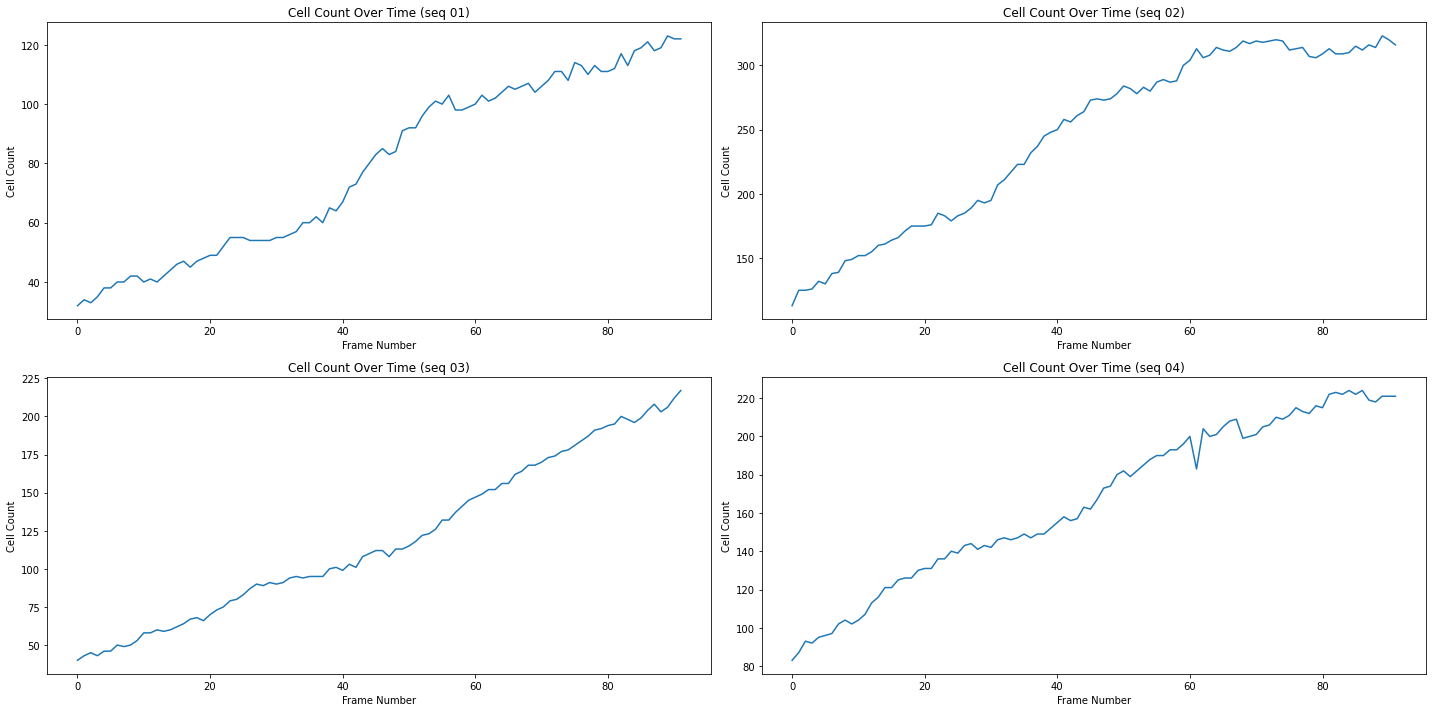

In [8]:
# calculate number of cells in each image
cell_count_1 = count_cells(data_path=seq_1)
cell_count_2 = count_cells(data_path=seq_2)
cell_count_3 = count_cells(data_path=seq_3)
cell_count_4 = count_cells(data_path=seq_4)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 10))

ax1.plot(range(len(cell_count_1)), cell_count_1)
ax1.set(title='Cell Count Over Time (seq 01)')
ax1.set_xlabel("Frame Number")
ax1.set_ylabel("Cell Count")

ax2.plot(range(len(cell_count_2)), cell_count_2)
ax2.set(title='Cell Count Over Time (seq 02)')
ax2.set_xlabel("Frame Number")
ax2.set_ylabel("Cell Count")

ax3.plot(range(len(cell_count_3)), cell_count_3)
ax3.set(title='Cell Count Over Time (seq 03)')
ax3.set_xlabel("Frame Number")
ax3.set_ylabel("Cell Count")

ax4.plot(range(len(cell_count_4)), cell_count_4)
ax4.set(title='Cell Count Over Time (seq 04)')
ax4.set_xlabel("Frame Number")
ax4.set_ylabel("Cell Count")

fig.tight_layout()
plt.show()

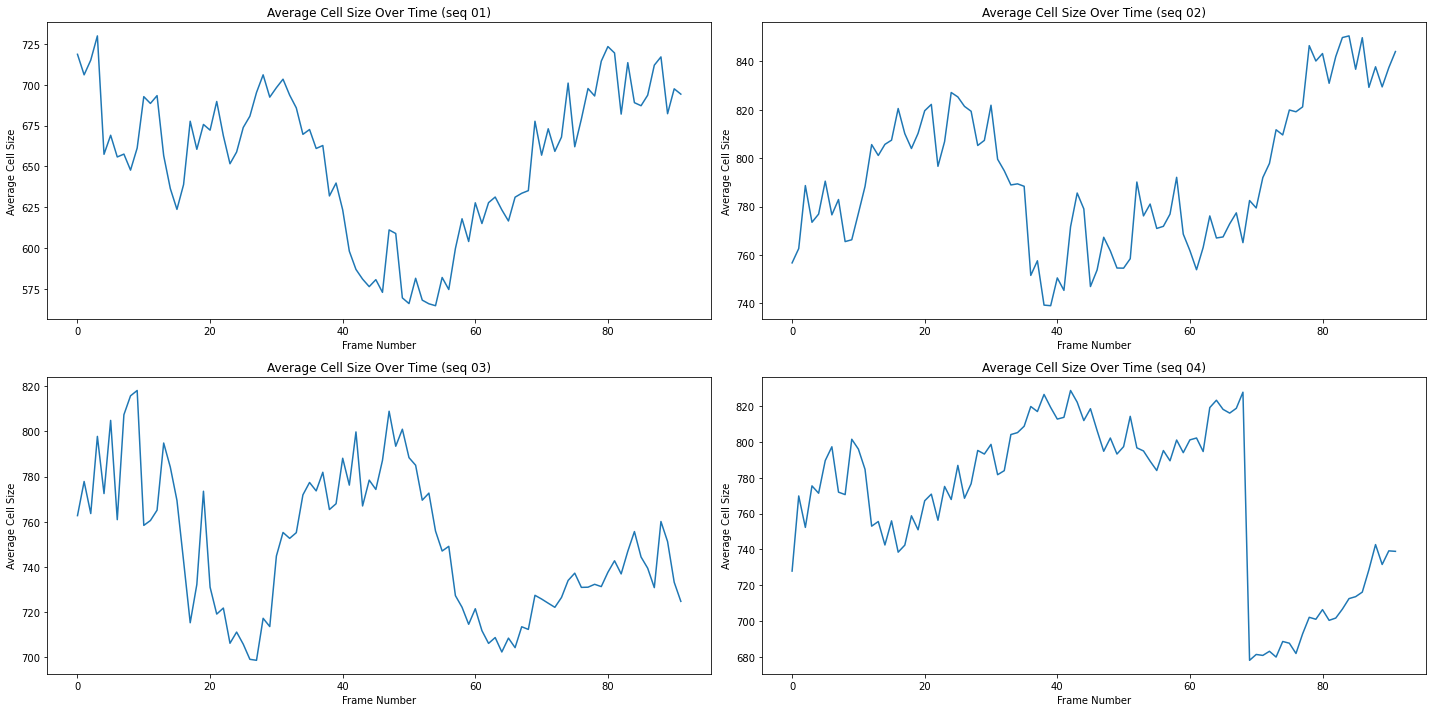

In [9]:
# calculate average cells size in each image
avg_cell_size_1 = get_average_cell_size(data_path=seq_1)
avg_cell_size_2 = get_average_cell_size(data_path=seq_2)
avg_cell_size_3 = get_average_cell_size(data_path=seq_3)
avg_cell_size_4 = get_average_cell_size(data_path=seq_4)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 10))

ax1.plot(range(len(avg_cell_size_1)), avg_cell_size_1)
ax1.set(title='Average Cell Size Over Time (seq 01)')
ax1.set_xlabel("Frame Number")
ax1.set_ylabel("Average Cell Size")

ax2.plot(range(len(avg_cell_size_2)), avg_cell_size_2)
ax2.set(title='Average Cell Size Over Time (seq 02)')
ax2.set_xlabel("Frame Number")
ax2.set_ylabel("Average Cell Size")

ax3.plot(range(len(avg_cell_size_3)), avg_cell_size_3)
ax3.set(title='Average Cell Size Over Time (seq 03)')
ax3.set_xlabel("Frame Number")
ax3.set_ylabel("Average Cell Size")

ax4.plot(range(len(avg_cell_size_4)), avg_cell_size_4)
ax4.set(title='Average Cell Size Over Time (seq 04)')
ax4.set_xlabel("Frame Number")
ax4.set_ylabel("Average Cell Size")

fig.tight_layout()
plt.show()

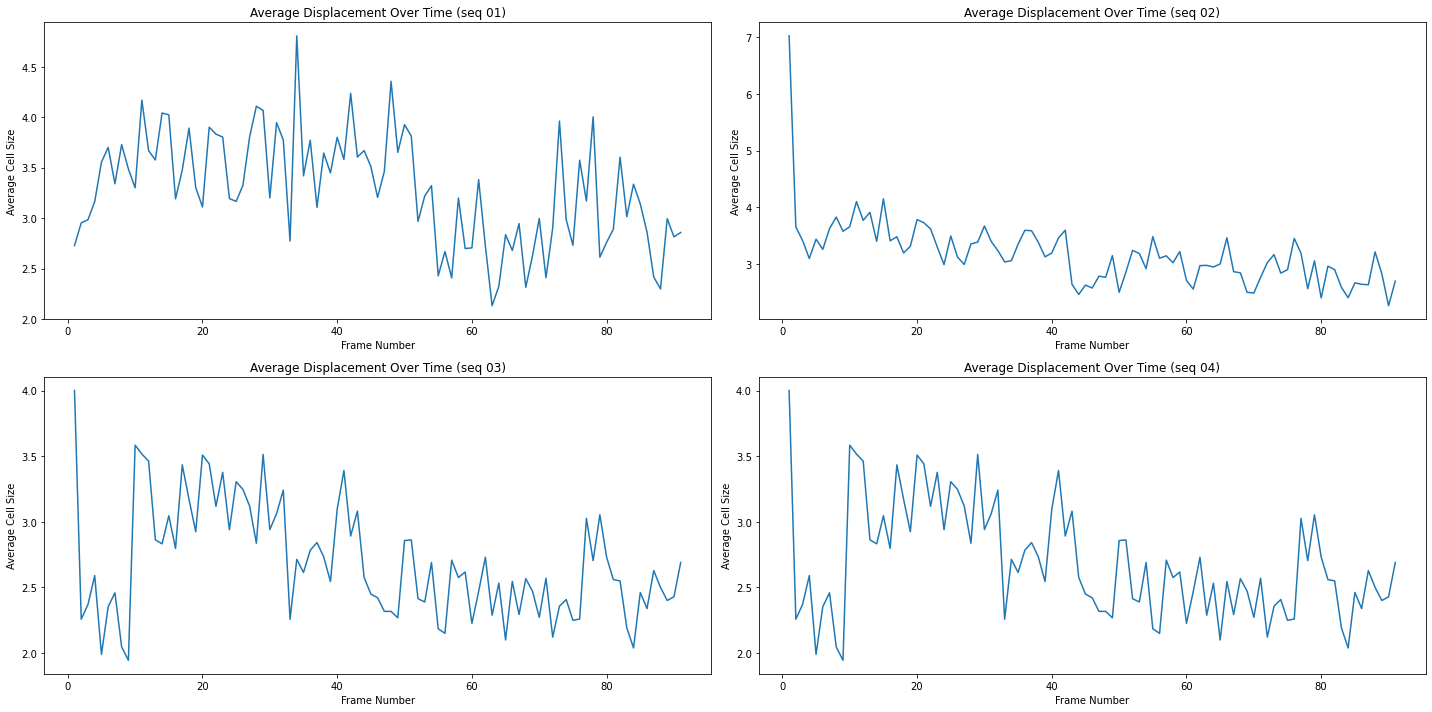

In [10]:
# plot displacements graph
avg_frame_displacements_1 = get_avg_displacements(cells_1)
avg_frame_displacements_2 = get_avg_displacements(cells_2)
avg_frame_displacements_3 = get_avg_displacements(cells_3)
avg_frame_displacements_4 = get_avg_displacements(cells_4)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 10))

ax1.plot(range(len(avg_frame_displacements_1)), avg_frame_displacements_1)
ax1.set(title='Average Displacement Over Time (seq 01)')
ax1.set_xlabel("Frame Number")
ax1.set_ylabel("Average Cell Size")

ax2.plot(range(len(avg_frame_displacements_2)), avg_frame_displacements_2)
ax2.set(title='Average Displacement Over Time (seq 02)')
ax2.set_xlabel("Frame Number")
ax2.set_ylabel("Average Cell Size")

ax3.plot(range(len(avg_frame_displacements_3)), avg_frame_displacements_3)
ax3.set(title='Average Displacement Over Time (seq 03)')
ax3.set_xlabel("Frame Number")
ax3.set_ylabel("Average Cell Size")

ax4.plot(range(len(avg_frame_displacements_3)), avg_frame_displacements_3)
ax4.set(title='Average Displacement Over Time (seq 04)')
ax4.set_xlabel("Frame Number")
ax4.set_ylabel("Average Cell Size")

fig.tight_layout()
plt.show()

## Display tracked cells

In [ ]:
# display tracked cells
# if wait_time = 0, press any key to go to the next frame
# press 'ESC' to quit
display_tracked_cells(images_1, avg_cell_size_1, avg_frame_displacements_1, wait_time=0, max_brightness=500)

# display_tracked_cells(images_2, avg_cell_size_2, avg_frame_displacements_2, wait_time=0, max_brightness=500)

# display_tracked_cells(images_3, avg_cell_size_3, avg_frame_displacements_3, wait_time=0, max_brightness=500)

# display_tracked_cells(images_4, avg_cell_size_4, avg_frame_displacements_4, wait_time=0, max_brightness=500)